*Part 1.*

Implement Selection-, Insertion- and Merge sort in Python.

All three algorithms must be tested with comprehensive tests.

In [8]:
# ============================================================
# Cell 1: Selection sort
# ============================================================

def selection_sort(array: list) -> list:
    length = len(array)
    for i in range(length-1):
        min_val = i
        for j in range(i+1,length):
            if array[j] < array[min_val]:
                min_val = j
        if min_val != i:
            array[i], array[min_val] = array[min_val], array[i]

    return array


example = [29, 72, 98, 13, 87]
print("Selection sort:", selection_sort(list(example)))

Selection sort: [13, 29, 72, 87, 98]


In [9]:
# ============================================================
# Cell 2: Insertion sort
# ============================================================

def insertion_sort(array:list) -> list:
    for i in range(1, len(array)):
        key = array[i]
        j = i-1
        while j >= 0 and key < array[j]:
            array[j+1] = array[j]
            j -= 1
        array[j+1] = key

    return array


example = [29, 72, 98, 13, 87]
print("Insertion sort:", insertion_sort(list(example)))

Insertion sort: [13, 29, 72, 87, 98]


In [10]:
# ============================================================
# Cell 3: Merge sort
# ============================================================

def merge_sort(array:list) -> list:
    if len(array) <=1:
        return array

    mid = len(array) // 2
    left = merge_sort(array[:mid])
    right = merge_sort(array[mid:])

    return merge(left, right)

def merge(left: list, right: list) -> list:
    sorted = []
    i = j = 0

    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            sorted.append(left[i])
            i += 1
        else:
            sorted.append(right[j])
            j += 1

    sorted.extend(left[i:])
    sorted.extend(right[j:])

    return sorted


example = [29, 72, 98, 13, 87]
print("Merge sort:", merge_sort(list(example)))

Merge sort: [13, 29, 72, 87, 98]


In [11]:
# ============================================================
# Cell 4: Tests for selection sort
# ============================================================

import random
import unittest


class SortTests:
    """Crucial tests shared by all three algorithms. Subclasses set `sort`."""
    sort = None

    def check(self, data):
        self.assertEqual(type(self).sort(list(data)), sorted(data))

    def test_empty_list(self):
        self.check([])

    def test_single_element(self):
        self.check([42])

    def test_already_sorted(self):
        self.check([1, 2, 3, 4, 5])

    def test_reverse_sorted(self):
        self.check([5, 4, 3, 2, 1])

    def test_duplicates(self):
        self.check([3, 1, 2, 3, 1])

    def test_negative_numbers(self):
        self.check([-3, 5, -1, 0, 8])

    def test_random_lists(self):
        rng = random.Random(42)
        for length in range(0, 30):
            data = [rng.randint(-100, 100) for _ in range(length)]
            with self.subTest(data=data):
                self.check(data)


class TestSelectionSort(SortTests, unittest.TestCase):
    sort = staticmethod(selection_sort)


unittest.main(argv=[""], defaultTest="TestSelectionSort", verbosity=2, exit=False)

test_already_sorted (__main__.TestSelectionSort.test_already_sorted) ... ok
test_duplicates (__main__.TestSelectionSort.test_duplicates) ... ok
test_empty_list (__main__.TestSelectionSort.test_empty_list) ... ok
test_negative_numbers (__main__.TestSelectionSort.test_negative_numbers) ... ok
test_random_lists (__main__.TestSelectionSort.test_random_lists) ... ok
test_reverse_sorted (__main__.TestSelectionSort.test_reverse_sorted) ... ok
test_single_element (__main__.TestSelectionSort.test_single_element) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.004s

OK


In [12]:
# ============================================================
# Cell 5: Tests for insertion sort
# ============================================================

class TestInsertionSort(SortTests, unittest.TestCase):
    sort = staticmethod(insertion_sort)


unittest.main(argv=[""], defaultTest="TestInsertionSort", verbosity=2, exit=False)

test_already_sorted (__main__.TestInsertionSort.test_already_sorted) ... ok
test_duplicates (__main__.TestInsertionSort.test_duplicates) ... ok
test_empty_list (__main__.TestInsertionSort.test_empty_list) ... ok
test_negative_numbers (__main__.TestInsertionSort.test_negative_numbers) ... ok
test_random_lists (__main__.TestInsertionSort.test_random_lists) ... ok
test_reverse_sorted (__main__.TestInsertionSort.test_reverse_sorted) ... ok
test_single_element (__main__.TestInsertionSort.test_single_element) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.003s

OK


In [13]:
# ============================================================
# Cell 6: Tests for merge sort
# ============================================================

class TestMergeSort(SortTests, unittest.TestCase):
    sort = staticmethod(merge_sort)


unittest.main(argv=[""], defaultTest="TestMergeSort", verbosity=2, exit=False)

test_already_sorted (__main__.TestMergeSort.test_already_sorted) ... ok
test_duplicates (__main__.TestMergeSort.test_duplicates) ... ok
test_empty_list (__main__.TestMergeSort.test_empty_list) ... ok
test_negative_numbers (__main__.TestMergeSort.test_negative_numbers) ... ok
test_random_lists (__main__.TestMergeSort.test_random_lists) ... ok
test_reverse_sorted (__main__.TestMergeSort.test_reverse_sorted) ... ok
test_single_element (__main__.TestMergeSort.test_single_element) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.004s

OK


**Part 2**

On large lists of numbers (use random, ascending and descending) plot the running time of the
three algorithms.
You can use time and matplotlib.pyplot (see “Plot_Example.ipynb” for code example) to compare
the algorithms.
Write what you expect from the plots and if this corresponds with the plots

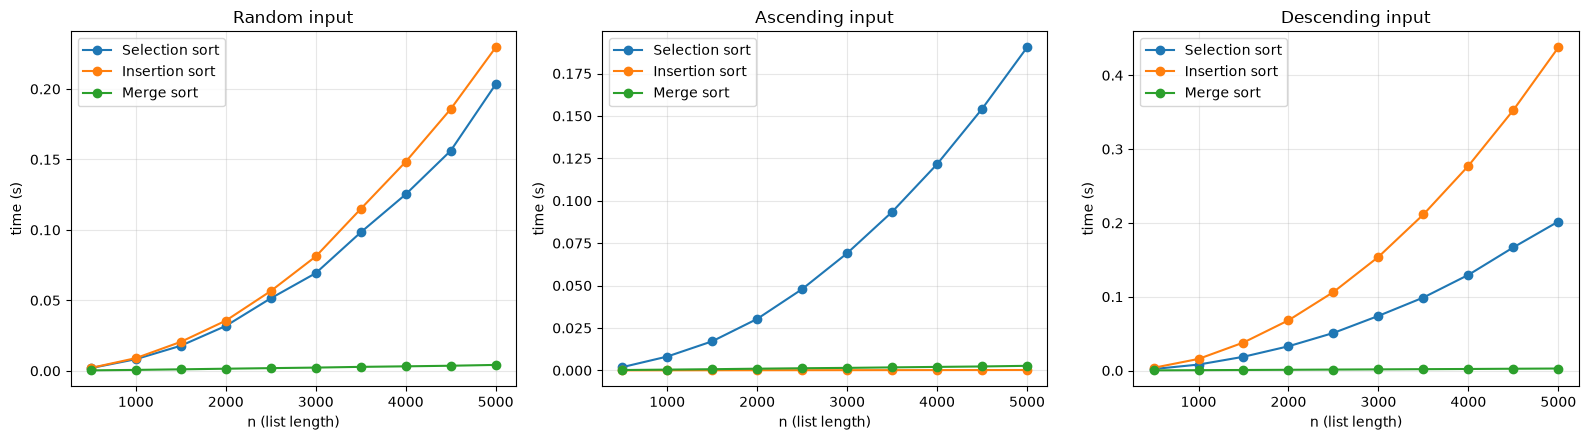

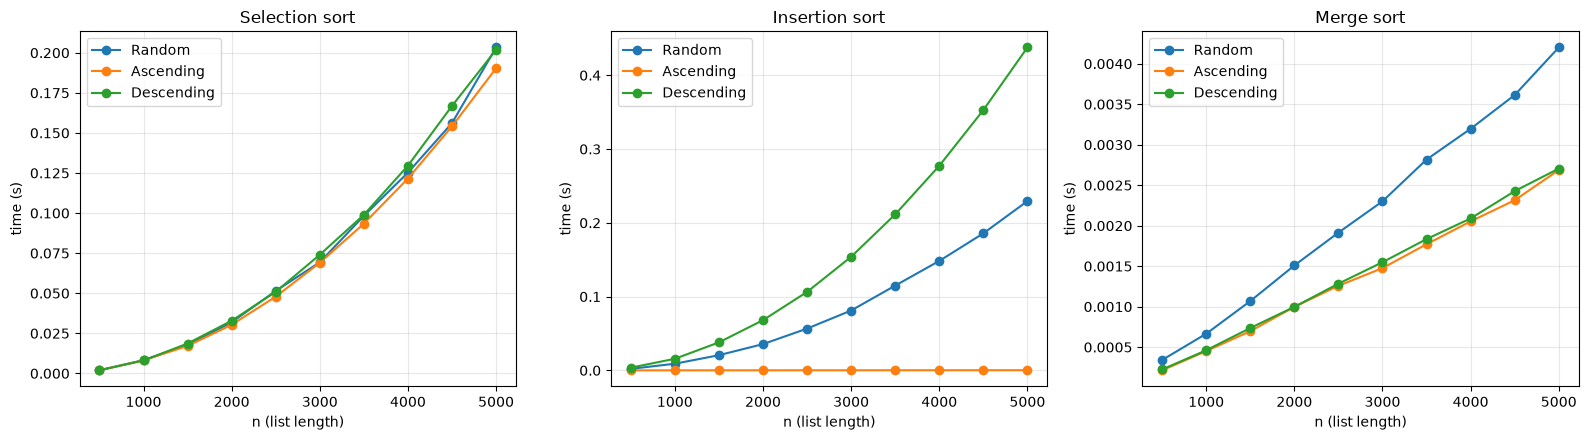

Running time (s) at n = 5000:
  Random     Selection sort: 0.2033, Insertion sort: 0.2294, Merge sort: 0.0042
  Ascending  Selection sort: 0.1903, Insertion sort: 0.0002, Merge sort: 0.0027
  Descending Selection sort: 0.2018, Insertion sort: 0.4377, Merge sort: 0.0027


In [14]:
# ============================================================
# Cell 7: Running time plots
# ============================================================

import random
import time
import matplotlib.pyplot as plt


def measure(sort, data, repeats=3):

    best = float("inf")
    for i in range(repeats):
        copy = list(data)  # selection/insertion sort work in place
        start = time.perf_counter()
        sort(copy)
        best = min(best, time.perf_counter() - start)
    return best


sizes = list(range(500, 5001, 500))
rng = random.Random(42)
inputs = {
    "Random": lambda n: rng.sample(range(n * 10), n),
    "Ascending": lambda n: list(range(n)),
    "Descending": lambda n: list(range(n, 0, -1)),
}
algorithms = {
    "Selection sort": selection_sort,
    "Insertion sort": insertion_sort,
    "Merge sort": merge_sort,
}

# times[input_name][algorithm_name] = list of running times, one per size
times = {name: {alg: [] for alg in algorithms} for name in inputs}
for name, make in inputs.items():
    for n in sizes:
        data = make(n)
        for alg_name, alg in algorithms.items():
            times[name][alg_name].append(measure(alg, data))

# Figure 1: one subplot per input type, comparing the algorithms
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, inputs):
    for alg_name in algorithms:
        ax.plot(sizes, times[name][alg_name], marker="o", label=alg_name)
    ax.set_title(f"{name} input")
    ax.set_xlabel("n (list length)")
    ax.set_ylabel("time (s)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

# Figure 2: one subplot per algorithm, comparing the input types
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, alg_name in zip(axes, algorithms):
    for name in inputs:
        ax.plot(sizes, times[name][alg_name], marker="o", label=name)
    ax.set_title(alg_name)
    ax.set_xlabel("n (list length)")
    ax.set_ylabel("time (s)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

# Times at the largest n, for the discussion below
print(f"Running time (s) at n = {sizes[-1]}:")
for name in inputs:
    row = ", ".join(f"{alg}: {times[name][alg][-1]:.4f}" for alg in algorithms)
    print(f"  {name:<10} {row}")

**Forventninger**

| | Tilfældig | Stigende | Faldende |
|---|---|---|---|
| Selection sort | Θ(n²) | Θ(n²) | Θ(n²) |
| Insertion sort | Θ(n²) (gennemsnitligt tilfælde) | Θ(n) (bedste tilfælde) | Θ(n²) (værste tilfælde) |
| Merge sort | Θ(n log n) | Θ(n log n) | Θ(n log n) |

- *Selection sort* gennemløber altid hele den usorterede del for at finde minimum, så den laver n(n−1)/2 sammenligninger, uanset hvordan inputtet ser ud. Jeg forventer tre næsten ens parabler.
- *Insertion sort* afhænger af, hvor langt hvert element skal flyttes tilbage. På stigende input stopper den indre `while`-løkke med det samme, så køretiden bør være lineær og tæt på nul. Faldende input er det værste tilfælde: hvert element flyttes hele vejen til forrest, omkring n²/2 flytninger. Det er cirka dobbelt så mange som de n²/4 flytninger, man kan forvente på tilfældigt input, så faldende input bør tage omkring dobbelt så lang tid som tilfældigt.
- *Merge sort* deler altid listen i halvdele og fletter på hvert niveau, så alle tre input bør give Θ(n log n). Det er langt under de to kvadratiske algoritmer. På sorteret input (stigende eller faldende) løber den ene halvdel tør efter omkring n/2 sammenligninger i hver fletning, så jeg forventer, at den er lidt hurtigere end på tilfældigt input.

**Passer plottene?**

Ja, de passer godt med teorien:

- *Selection sort*: de tre kurver ligger praktisk talt oven i hinanden og vokser kvadratisk. Når n fordobles fra 2000 til 4000, bliver køretiden omkring 4 gange længere. Faldende input er en smule langsommere, fordi der laves flere ombytninger, men sammenligningerne dominerer.
- *Insertion sort*: kurven for stigende input er flad ved næsten 0 s. Faldende input er omkring dobbelt så langsomt som tilfældigt (≈ 0,45 s mod ≈ 0,23 s ved n = 5000), som forudsagt. På stigende input er insertion sort den hurtigste af alle tre algoritmer, endda hurtigere end merge sort, fordi den kun laver ét gennemløb.
- *Merge sort*: kurverne ligner næsten rette linjer (n log n vokser kun lidt hurtigere end n) og er omkring 50–100× hurtigere end de kvadratiske algoritmer ved n = 5000. Som forventet er stigende og faldende input hurtigere end tilfældigt input (omkring 1,6× her).

Én ting viser den asymptotiske analyse ikke: på tilfældigt input er insertion sort en smule *langsommere* end selection sort, selvom den laver færre sammenligninger (≈ n²/4 mod n²/2). Hvert skridt i insertion sorts indre løkke laver mere arbejde i Python: to betingelser, en flytning af et element og en nedtælling. Selection sorts indre løkke laver kun én sammenligning. Konstantfaktorerne er altså forskellige, og det betyder noget i praksis, selv når Store-O-klassen er den samme.